In [1]:
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large',
       titleweight='bold', titlesize=18, titlepad=10)

In [2]:
import pandas as pd

red_wine = pd.read_csv('../datasets/dl-course-data/red-wine.csv')

# Create training and validation splits
df_train = red_wine.sample(frac=0.7, random_state=0)
df_valid = red_wine.drop(df_train.index)

X_train = df_train.drop('quality', axis=1)
y_train = df_train['quality']

X_valid = df_valid.drop('quality', axis=1)
y_valid = df_valid['quality']

In [3]:
from tensorflow.keras import Sequential, layers

INPUT_SHAPE, HIDDEN_SHAPE, OUTPUT_SHAPE = 11, 1024, 1
DROPOUT_RATE = 0.3
ReLU = 'relu'

model = Sequential([
    layers.Input(shape=[INPUT_SHAPE]),
    
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),
    layers.Dropout(DROPOUT_RATE),
    layers.BatchNormalization(),
    
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),
    layers.Dropout(DROPOUT_RATE),
    layers.BatchNormalization(),
    
    layers.Dense(HIDDEN_SHAPE, activation=ReLU),
    layers.Dropout(DROPOUT_RATE),
    layers.BatchNormalization(),
    
    layers.Dense(OUTPUT_SHAPE),
])

2025-01-23 10:38:52.263048: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-23 10:38:52.275152: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-23 10:38:52.306141: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1737628732.362576   21340 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737628732.375505   21340 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-01-23 10:38:52.422075: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU ins

In [4]:
model.compile(
    optimizer='adam',
    loss='mae',
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=256,
    epochs=100,
    verbose=0,
)

<Axes: >

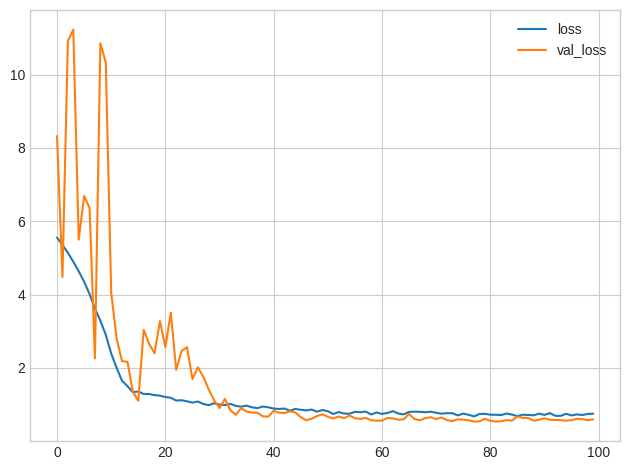

In [5]:
# Show the learning curves
history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot()